## Coffee shop EDA and sales analysis

In [1]:
import os

import matplotlib.pyplot as plt             # easier to call
import pandas as pd
import seaborn as sns

DATASET_FOLDER = "data/"                    # path where data is
CHART_FOLDER = "charts/"                    # path where to save charts

os.makedirs(CHART_FOLDER, exist_ok=True)
os.makedirs(DATASET_FOLDER, exist_ok=True)

# CHART PARAMETERS
COLOR = "#55A868"
SNS_HEATMAP_COLOR = "Greens"
plt.rcParams["svg.fonttype"] = "none"       # keeps chart text as real text
plt.rcParams["figure.figsize"] = (6, 3.6)   # every chart gets this size
plt.rcParams["figure.autolayout"] = True    # to automatically adapt for less headaches

# Load and check dataset

In [2]:
# Load and view first few rows from top
sales = pd.read_excel(DATASET_FOLDER + "Coffe_sales.xlsx")

sales.head()

,date,datetime,hour_of_day,cash_type,card,money,coffee_name,Time_of_Day,Weekday,Month_name,Weekdaysort,Monthsort
0,2024-03-01,2024-03-01 10:15:50.520,10,card,ANON-0000-0000-0001,38.7,Latte,Morning,Fri,Mar,5,3
1,2024-03-01,2024-03-01 12:19:22.539,12,card,ANON-0000-0000-0002,38.7,Hot Chocolate,Afternoon,Fri,Mar,5,3
2,2024-03-01,2024-03-01 12:20:18.089,12,card,ANON-0000-0000-0002,38.7,Hot Chocolate,Afternoon,Fri,Mar,5,3
3,2024-03-01,2024-03-01 13:46:33.006,13,card,ANON-0000-0000-0003,28.9,Americano,Afternoon,Fri,Mar,5,3
4,2024-03-01,2024-03-01 13:48:14.626,13,card,ANON-0000-0000-0004,38.7,Latte,Afternoon,Fri,Mar,5,3


In [3]:
# simple dataset info summary
sales.info()

# summary of missing stuff (fully objective)
print(sales.isnull().sum())

# checks if the reason for the blank card entries is because it's in cash. if not, throw error
is_cash = sales.cash_type == "cash"
assert sales.card.isna().sum() == is_cash.sum()

# regroup by year+month, not month name because data holds two Marches (2024 and 2025).
sales["year_month"] = sales.date.dt.to_period("M")

# total duplicates, if any
duplicates = sales.duplicated().sum()
print(f'Number of duplicate rows: {duplicates}')

<class 'pandas.DataFrame'>
RangeIndex: 3636 entries, 0 to 3635
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         3636 non-null   datetime64[us]
 1   datetime     3636 non-null   datetime64[us]
 2   hour_of_day  3636 non-null   int64         
 3   cash_type    3636 non-null   str           
 4   card         3547 non-null   str           
 5   money        3636 non-null   float64       
 6   coffee_name  3636 non-null   str           
 7   Time_of_Day  3636 non-null   str           
 8   Weekday      3636 non-null   str           
 9   Month_name   3636 non-null   str           
 10  Weekdaysort  3636 non-null   int64         
 11  Monthsort    3636 non-null   int64         
dtypes: datetime64[us](2), float64(1), int64(3), str(6)
memory usage: 341.0 KB
date            0
datetime        0
hour_of_day     0
cash_type       0
card           89
money           0
coffee_name     0
Time_of_Day  

## Headline numbers

In [4]:
# Self-explanatory.

total_revenue = sales.money.sum()
number_of_sales = len(sales)
average_sale = sales.money.mean()
trading_days = sales.date.nunique()
cash_share = is_cash.mean()

print(f"Total revenue:  {total_revenue:,.0f}")
print(f"Total sales:    {number_of_sales:,}")
print(f"Average sale:   {average_sale:.2f}")
print(f"Trading days:   {trading_days}")
print(f"% paid in cash: {cash_share:.1%}")

Total revenue:  115,432
Total sales:    3,636
Average sale:   31.75
Trading days:   381
% paid in cash: 2.4%


## EDA and Plotting

In [5]:
# Price charged ranges
# Lowest price, highest price and number of different prices charged, per drink
sales.groupby("coffee_name").money.agg(["min", "max", "nunique"]).round(1)

,min,max,nunique
coffee_name,,,
Americano,23.0,30.0,6
Americano with Milk,27.9,35.0,6
Cappuccino,32.8,40.0,6
Cocoa,32.8,40.0,6
Cortado,23.0,30.0,5
Espresso,18.1,25.0,5
Hot Chocolate,32.8,40.0,6
Latte,32.8,40.0,6


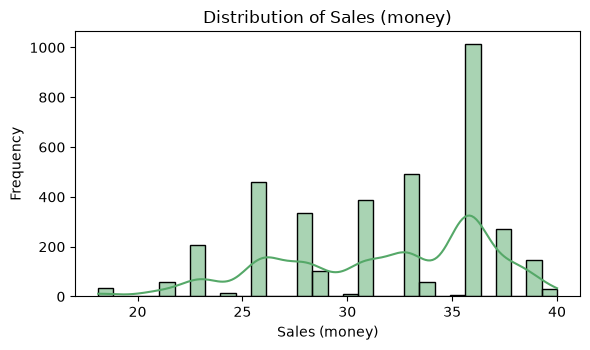

In [6]:
# Sales and Sales distribution
sales.money.describe().round(2)

fig, ax = plt.subplots()
sns.histplot(data=sales, x="money", bins=30, kde=True, color=COLOR, ax=ax)
plt.title('Distribution of Sales (money)')
plt.xlabel('Sales (money)')
plt.ylabel('Frequency')
plt.savefig(CHART_FOLDER + "c_sales_hist.svg")

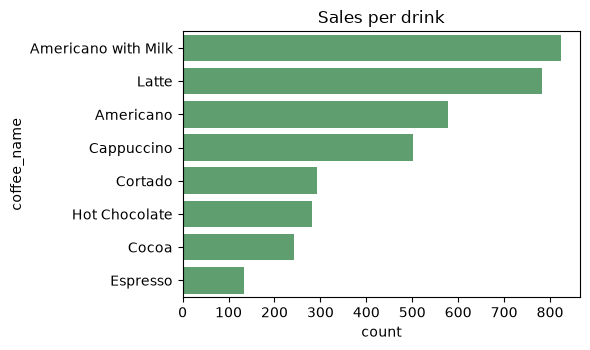

In [7]:
# Sales Per Drink / Popularity Count Plot
fig, ax = plt.subplots()
sns.countplot(data=sales, y="coffee_name", order=sales.coffee_name.value_counts().index, color=COLOR, ax=ax)
ax.set_title("Sales per drink")
fig.savefig(CHART_FOLDER + "c_drink_counts.svg")

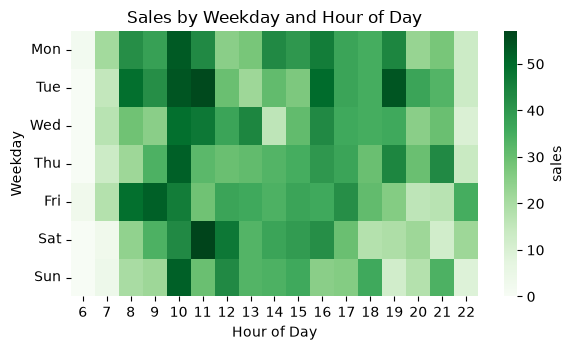

In [8]:
# crosstab counts rows for each combination; reindex puts the days in calendar order
order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
busy = pd.crosstab(sales.Weekday, sales.hour_of_day).reindex(order)

fig, ax = plt.subplots()
sns.heatmap(busy, cmap=SNS_HEATMAP_COLOR, cbar_kws={"label": "sales"}, ax=ax)
ax.set_title("Sales by Weekday and Hour of Day")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Weekday")
plt.setp(ax.get_yticklabels(), rotation=0)                   # upright weekday labels
fig.savefig(CHART_FOLDER + "c_weekday_hour.svg")

## KPI Analysis

In [9]:
# Revenue per month 
# The last month is incomplete (the data ends on March 23)
# which is why I compare sales by day rather than month for fair analysis
monthly = sales.groupby("year_month").agg(
    revenue=("money", "sum"),
    trading_days=("date", "nunique"),
)
monthly["revenue_per_day"] = monthly.revenue / monthly.trading_days

monthly.round(0)              # found this out at random, turns out a bare line with a variable can show an output on jupyter

,revenue,trading_days,revenue_per_day
year_month,,,
2024-03,7050.0,31,227.0
2024-04,6721.0,30,224.0
2024-05,9063.0,28,324.0
2024-06,7759.0,30,259.0
2024-07,6916.0,31,223.0
2024-08,7614.0,31,246.0
2024-09,9989.0,30,333.0
2024-10,13891.0,31,448.0
2024-11,8591.0,29,296.0


In [10]:
# Revenue and cups sold per drink
# Best seller first.
drinks = sales.groupby("coffee_name").agg(
    revenue=("money", "sum"),
    cups=("money", "size"),
)
drinks = drinks.sort_values("revenue", ascending=False)
drinks["share_of_revenue"] = drinks.revenue / total_revenue

drinks.round(3)

,revenue,cups,share_of_revenue
coffee_name,,,
Latte,27866.30,782,0.241
Americano with Milk,25269.12,824,0.219
Cappuccino,18034.14,501,0.156
Americano,15062.26,578,0.130
Hot Chocolate,10172.46,282,0.088
Cocoa,8678.16,243,0.075
Cortado,7534.86,292,0.065
Espresso,2814.28,134,0.024


In [11]:
# Sales per hour
# The number of sales in each hour of the day.
sales_per_hour = sales.groupby("hour_of_day").size()

sales_per_hour

hour_of_day
6       5
7      91
8     235
9     247
10    349
11    294
12    249
13    227
14    228
15    245
16    282
17    245
18    220
19    235
20    171
21    197
22    116
dtype: int64

In [12]:
# Average revenue per trading day for each weekday
# `Weekdaysort` (the numbering system of 1 = mon to 7 = sun)
# is included in the grouping so the days stay in calendar order, then dropped.
weekdays = sales.groupby(["Weekdaysort", "Weekday"]).agg(
    revenue=("money", "sum"),
    trading_days=("date", "nunique"),
)
weekdays["revenue_per_day"] = weekdays.revenue / weekdays.trading_days
weekdays = weekdays.droplevel("Weekdaysort")

weekdays.round(0)

,revenue,trading_days,revenue_per_day
Weekday,,,
Mon,17925.0,55,326.0
Tue,18637.0,55,339.0
Wed,16093.0,52,309.0
Thu,16477.0,54,305.0
Fri,17258.0,56,308.0
Sat,15183.0,55,276.0
Sun,13858.0,54,257.0


## Data Analysis Charting
Saved as an SVG file in the `charts/` folder.

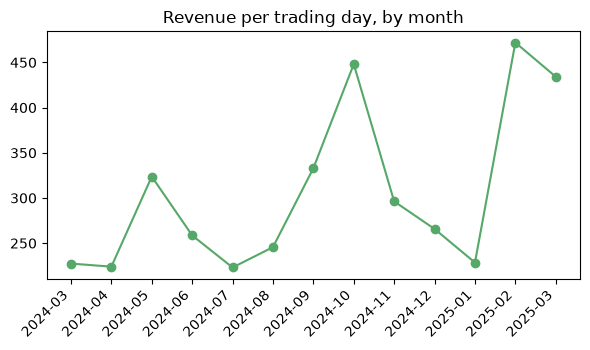

In [13]:
# Revenue per trading day, by month
fig, ax = plt.subplots()
ax.plot(monthly.index.astype(str), monthly.revenue_per_day, marker="o", color=COLOR)
ax.set_title("Revenue per trading day, by month")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")     # tilted so the month labels fit
fig.savefig(CHART_FOLDER + "c_monthly_revenue.svg")

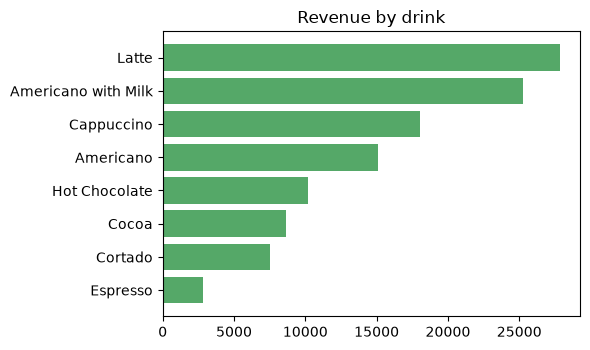

In [14]:
# Revenue by drink (horizontal bars suit the long names)
fig, ax = plt.subplots()
ax.barh(drinks.index, drinks.revenue, color=COLOR)
ax.invert_yaxis()                                           # best seller on top
ax.set_title("Revenue by drink")
fig.savefig(CHART_FOLDER + "c_revenue_by_product.svg")

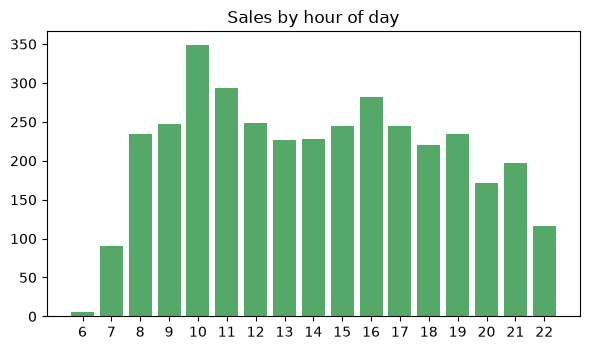

In [15]:
# Sales by hour of day
fig, ax = plt.subplots()
ax.bar(sales_per_hour.index, sales_per_hour.to_numpy(), color=COLOR)
ax.set_xticks(sales_per_hour.index)                         # label every hour
ax.set_title("Sales by hour of day")
fig.savefig(CHART_FOLDER + "c_sales_by_day_hour.svg")

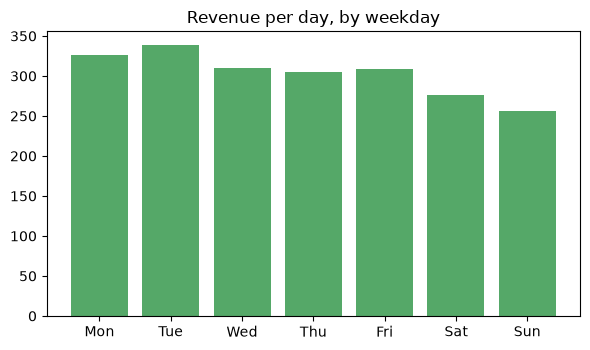

In [16]:
# Revenue per day, by weekday
fig, ax = plt.subplots()
ax.bar(weekdays.index, weekdays.revenue_per_day, color=COLOR)
ax.set_title("Revenue per day, by weekday")
fig.savefig(CHART_FOLDER + "c_revenue_per_day_by_weekday.svg")